# Лабораторна робота № 4 (2)
## Аналіз і візуалізація даних засобами Seaborn

**Дисципліна:** Комп’ютерні системи візуалізації даних  
**Студент:** Климченко Владислав Сергійович  
**Група:** 4-3з  

**Мета роботи:** опрацювати табличні дані засобами Pandas, дослідити часові ряди та статистичні характеристики і побудувати інформативні графіки за допомогою Seaborn і Matplotlib.

**Середовище:** Google Colab / Jupyter Notebook.  
**Дані:** файл `Museum_Visitors.csv` (фактична назва завантаженого файлу може відрізнятися) та датасет `penguins`.

**Вимоги до виконання:** заповніть порожні кодові комірки, виконайте їх послідовно, збережіть виведені таблиці та графіки. Кожен графік повинен мати зрозумілий заголовок і підписи осей. Не змінюйте формулювання завдань.

## Частина 1. Датасет Museum Visitors

Дані містять місячну відвідуваність музеїв і культурних об’єктів Лос-Анджелеса. У вихідній таблиці — один стовпець із датою та 11 стовпців із кількістю відвідувачів.

| Стовпець | Зміст |
|:--|:--|
| `Month` | Місяць і рік спостереження |
| `America Tropical Interpretive Center` | Кількість відвідувачів центру America Tropical |
| `Avila Adobe` | Відвідувачі історичної будівлі Avila Adobe |
| `Chinese American Museum` | Відвідувачі Китайсько-Американського музею |
| `Gateway to Nature Center` | Відвідувачі центру Gateway to Nature |
| `Firehouse Museum` | Відвідувачі пожежного музею |
| `Hellman Quon` | Відвідувачі історичної будівлі Hellman Quon |
| `IAMLA` | Відвідувачі Італійсько-Американського музею Лос-Анджелеса |
| `Pico House` | Відвідувачі історичної будівлі Pico House |
| `Visitor Center/ El Tranquilo Gallery` | Відвідувачі центру та галереї El Tranquilo |
| `Museum of Social Justice` | Відвідувачі Музею соціальної справедливості |
| `Biscailuz Gallery/ PK Outdoor Exhibit` | Відвідувачі галереї та відкритої експозиції |

**Увага:** відсутнє значення (`NaN`) не обов'язково означає нульову відвідуваність. Деякі об’єкти мають дані лише за частину періоду. Це потрібно враховувати в розрахунках.

### Завдання 1. Імпорт бібліотек

Імпортуйте `pandas`, `numpy`, `matplotlib.pyplot` та `seaborn`. Для роботи в Google Colab за потреби використайте засоби завантаження локального CSV-файлу.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# у Colab файл завантажується вручну, локально - читається з папки з ноутбуком
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = 'Museum_Visitors.csv'

print('Файл:', file_name)

Файл: Museum_Visitors.csv


### Завдання 2. Завантаження даних

Завантажте файл **Museum Visitors** у DataFrame `df`. Виведіть перші п’ять рядків таблиці та її розмірність.

In [2]:
df = pd.read_csv(file_name)
display(df.head())
print('Розмірність:', df.shape)

,Month,America Tropical Interpretive Center,Avila Adobe,Chinese American Museum,Gateway to Nature Center,Firehouse Museum,Hellman Quon,IAMLA,Pico House,Visitor Center/ El Tranquilo Gallery,Museum of Social Justice,Biscailuz Gallery/ PK Outdoor Exhibit
0,01/01/2014 12:00:00 AM,6602,24778,1581,NaN,4486,0.0,NaN,2204.0,2961.0,NaN,NaN
1,02/01/2014 12:00:00 AM,5029,18976,1785,NaN,4172,0.0,NaN,1330.0,2276.0,NaN,NaN
2,03/01/2014 12:00:00 AM,8129,25231,3229,NaN,7082,70.0,NaN,4320.0,3116.0,NaN,NaN
3,04/01/2014 12:00:00 AM,2824,26989,2129,NaN,6756,250.0,NaN,3277.0,2808.0,NaN,NaN
4,05/01/2014 12:00:00 AM,10694,36883,3676,NaN,10858,135.0,NaN,4122.0,3987.0,NaN,NaN


Розмірність: (85, 12)


### Завдання 3. Первинний аналіз

Визначте типи даних, кількість непорожніх значень у стовпцях та основні описові статистики числових ознак.

In [3]:
df.info()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Month                                  85 non-null     object 
 1   America Tropical Interpretive Center   85 non-null     int64  
 2   Avila Adobe                            85 non-null     int64  
 3   Chinese American Museum                85 non-null     int64  
 4   Gateway to Nature Center               32 non-null     float64
 5   Firehouse Museum                       85 non-null     int64  
 6   Hellman Quon                           26 non-null     float64
 7   IAMLA                                  54 non-null     float64
 8   Pico House                             83 non-null     float64
 9   Visitor Center/ El Tranquilo Gallery   45 non-null     float64
 10  Museum of Social Justice               37 non-null     float64
 11  Biscailu

,count,mean,std,min,25%,50%,75%,max
America Tropical Interpretive Center,85.0,5637.694118,3277.453044,0.0,3891.00,5705.0,6955.00,13490.0
Avila Adobe,85.0,19904.952941,9495.340548,0.0,17056.00,20815.0,25234.00,41242.0
Chinese American Museum,85.0,2359.117647,1360.427221,0.0,1785.00,2371.0,2808.00,7702.0
Gateway to Nature Center,32.0,1247.375000,1212.137535,0.0,0.00,1138.0,1882.50,4227.0
Firehouse Museum,85.0,5286.776471,6591.535926,0.0,3858.00,4613.0,5406.00,61192.0
Hellman Quon,26.0,353.461538,447.043106,0.0,81.25,180.0,458.75,2000.0
IAMLA,54.0,882.611111,507.197681,0.0,685.00,1020.0,1202.25,1883.0
Pico House,83.0,1329.710843,1832.519767,0.0,177.50,605.0,1597.50,9312.0
Visitor Center/ El Tranquilo Gallery,45.0,2634.800000,2055.530871,0.0,1769.00,2751.0,3323.00,13750.0
Museum of Social Justice,37.0,2125.972973,1954.845497,0.0,0.00,2557.0,2911.00,10740.0


### Завдання 4. Перевірка дублікатів

Обчисліть кількість повністю дубльованих рядків. За наявності дублікатів поясніть, як із ними потрібно вчинити.

In [4]:
dup = df.duplicated().sum()
print('Кількість повністю дубльованих рядків:', dup)
print('Кількість повторів у стовпці Month:', df['Month'].duplicated().sum())

Кількість повністю дубльованих рядків: 0
Кількість повторів у стовпці Month: 0


**Висновок.** Повністю дубльованих рядків немає, і кожен місяць зустрічається в таблиці лише один раз, тому нічого видаляти не треба. Якби дублікати були, їх варто було б прибрати через `df.drop_duplicates()`, бо інакше один і той самий місяць враховувався б двічі й завищував суми та середні.

### Завдання 5. Дослідження пропущених значень

Визначте кількість пропусків для кожного стовпця. Запропонуйте обґрунтований підхід до їх опрацювання. **Не заповнюйте пропуски середнім значенням автоматично:** це може створювати неіснуючі відвідування та спотворювати статистику.

In [5]:
missing = pd.DataFrame({
    'пропусків': df.isna().sum(),
    'частка, %': (df.isna().mean() * 100).round(1)
})
display(missing)

# з якого і по який місяць є дані для кожного об'єкта
for col in df.columns[1:]:
    s = df.loc[df[col].notna(), 'Month']
    print(f'{col}: {s.iloc[0][:10]} - {s.iloc[-1][:10]}, записів: {len(s)}')

,пропусків,"частка, %"
Month,0,0.0
America Tropical Interpretive Center,0,0.0
Avila Adobe,0,0.0
Chinese American Museum,0,0.0
Gateway to Nature Center,53,62.4
Firehouse Museum,0,0.0
Hellman Quon,59,69.4
IAMLA,31,36.5
Pico House,2,2.4
Visitor Center/ El Tranquilo Gallery,40,47.1


America Tropical Interpretive Center: 01/01/2014 - 01/01/2021, записів: 85
Avila Adobe: 01/01/2014 - 01/01/2021, записів: 85
Chinese American Museum: 01/01/2014 - 01/01/2021, записів: 85
Gateway to Nature Center: 05/01/2017 - 01/01/2021, записів: 32
Firehouse Museum: 01/01/2014 - 01/01/2021, записів: 85
Hellman Quon: 01/01/2014 - 02/01/2016, записів: 26
IAMLA: 05/01/2017 - 01/01/2021, записів: 54
Pico House : 01/01/2014 - 01/01/2021, записів: 83
Visitor Center/ El Tranquilo Gallery: 01/01/2014 - 09/01/2017, записів: 45
Museum of Social Justice: 03/01/2018 - 01/01/2021, записів: 37
Biscailuz Gallery/ PK Outdoor Exhibit: 05/01/2017 - 01/01/2021, записів: 39


**Підхід до пропусків.** Пропуски розподілені не випадково. Вони з'являються там, де об'єкт ще не працював або вже не подавав дані: Hellman Quon має дані тільки до 02.2016, Visitor Center – до 09.2017, Gateway to Nature Center, IAMLA і Biscailuz Gallery – з 05.2017, Museum of Social Justice – з 03.2018. Тому заповнювати їх середнім чи нулями не можна: середнє «створило б» відвідувачів, яких не було, а нулі занизили б показники. Я залишаю `NaN` як є, а pandas при обчисленні `mean()`, `min()`, `max()` і `corr()` пропускає їх автоматично. Для порівнянь між музеями окремо вказую кількість місяців з даними.

### Завдання 6. Підготовка назв і дат

Приведіть назви стовпців до зручного для програмування вигляду (нижній регістр, підкреслення замість пробілів і роздільників). Переконайтеся, що немає зайвих підкреслень на початку чи в кінці назв. Перетворіть `Month` на тип дати та перевірте результат.

In [6]:
df.columns = (df.columns.str.strip()
                         .str.lower()
                         .str.replace(r'[^a-z0-9]+', '_', regex=True)
                         .str.strip('_'))
df['month'] = pd.to_datetime(df['month'], format='%m/%d/%Y %I:%M:%S %p')

museums = [c for c in df.columns if c != 'month']
print(list(df.columns))
print(df['month'].dtype)
print('Період:', df['month'].min().date(), '-', df['month'].max().date())

['month', 'america_tropical_interpretive_center', 'avila_adobe', 'chinese_american_museum', 'gateway_to_nature_center', 'firehouse_museum', 'hellman_quon', 'iamla', 'pico_house', 'visitor_center_el_tranquilo_gallery', 'museum_of_social_justice', 'biscailuz_gallery_pk_outdoor_exhibit']
datetime64[ns]
Період: 2014-01-01 - 2021-01-01


### Завдання 7. Мінімальна і максимальна відвідуваність у 2018 році

Відберіть записи **за 2018 рік**. Для кожного музею обчисліть мінімальне та максимальне **фактично наявне** місячне значення відвідуваності. Подайте результати у вигляді таблиці. Якщо за цей рік немає даних про певний музей, не підміняйте їх середнім за інші роки.

In [7]:
df_2018 = df[df['month'].dt.year == 2018]

stats_2018 = pd.DataFrame({
    'мінімум': df_2018[museums].min(),
    'максимум': df_2018[museums].max(),
    'місяців з даними': df_2018[museums].count()
})
display(stats_2018)

,мінімум,максимум,місяців з даними
america_tropical_interpretive_center,3180.0,5837.0,12
avila_adobe,14718.0,25173.0,12
chinese_american_museum,2078.0,4960.0,12
gateway_to_nature_center,NaN,NaN,0
firehouse_museum,3306.0,8013.0,12
hellman_quon,NaN,NaN,0
iamla,965.0,1601.0,12
pico_house,185.0,2140.0,11
visitor_center_el_tranquilo_gallery,NaN,NaN,0
museum_of_social_justice,2332.0,3686.0,12


### Завдання 8. Середня відвідуваність

Обчисліть середню місячну кількість відвідувачів для кожного музею **за доступними спостереженнями**. Додатково виведіть кількість місяців, за якими розраховано середнє, щоб можна було правильно порівнювати результати.

In [8]:
mean_visits = pd.DataFrame({
    'середнє за місяць': df[museums].mean().round(1),
    'кількість місяців': df[museums].count()
}).sort_values('середнє за місяць', ascending=False)
display(mean_visits)

,середнє за місяць,кількість місяців
avila_adobe,19905.0,85
america_tropical_interpretive_center,5637.7,85
firehouse_museum,5286.8,85
visitor_center_el_tranquilo_gallery,2634.8,45
chinese_american_museum,2359.1,85
museum_of_social_justice,2126.0,37
pico_house,1329.7,83
gateway_to_nature_center,1247.4,32
biscailuz_gallery_pk_outdoor_exhibit,1088.6,39
iamla,882.6,54


### Завдання 9. Найменша та найбільша сумарна відвідуваність у 2015 році

Визначте місяці **2015 року** з найменшою та найбільшою сумарною кількістю відвідувачів. Для коректного порівняння використайте однаковий набір музеїв, для яких є дані в усіх 12 місяцях 2015 року, або обґрунтуйте інший спосіб забезпечення порівнюваності.

In [9]:
df_2015 = df[df['month'].dt.year == 2015]

# беремо тільки музеї, по яких є дані за всі 12 місяців 2015 року
full_2015 = [c for c in museums if df_2015[c].count() == 12]
print('Музеї з повними даними за 2015 рік:', full_2015)

total_2015 = df_2015.set_index('month')[full_2015].sum(axis=1)
print('\nНайменша відвідуваність:', total_2015.idxmin().strftime('%m.%Y'), '-', int(total_2015.min()))
print('Найбільша відвідуваність:', total_2015.idxmax().strftime('%m.%Y'), '-', int(total_2015.max()))

Музеї з повними даними за 2015 рік: ['america_tropical_interpretive_center', 'avila_adobe', 'chinese_american_museum', 'firehouse_museum', 'hellman_quon', 'pico_house', 'visitor_center_el_tranquilo_gallery']

Найменша відвідуваність: 02.2015 - 30771
Найбільша відвідуваність: 05.2015 - 73429


**Пояснення.** Visitor Center, Hellman Quon та інші об'єкти мають різну кількість місяців з даними, тому для порівняння місяців 2015 року я взяв лише ті музеї, де є всі 12 значень. Так сума в кожному місяці складається з однакового набору музеїв. Найменше відвідувачів було у лютому, найбільше – у травні 2015 року.

### Завдання 10. Сезонне порівняння для Avila Adobe

Для музею **Avila Adobe** обчисліть сумарну кількість відвідувачів **улітку 2018 року (червень–серпень 2018)** і **взимку 2017/2018 (грудень 2017 — лютий 2018)**. Порівняйте отримані значення.

In [10]:
avila = df.set_index('month')['avila_adobe']

summer_2018 = avila['2018-06-01':'2018-08-01'].sum()
winter_2017 = avila['2017-12-01':'2018-02-01'].sum()

print('Літо 2018 (червень-серпень):', int(summer_2018))
print('Зима 2017/2018 (грудень-лютий):', int(winter_2017))
print('Різниця:', int(summer_2018 - winter_2017))
print('Влітку відвідувачів більше в', round(summer_2018 / winter_2017, 2), 'раза')

Літо 2018 (червень-серпень): 66122
Зима 2017/2018 (грудень-лютий): 49322
Різниця: 16800
Влітку відвідувачів більше в 1.34 раза


**Порівняння.** Улітку 2018 року Avila Adobe відвідало 66 122 особи, а взимку 2017/2018 – 49 322, тобто влітку приблизно на 34 % більше. Це пояснюється туристичним сезоном і канікулами.

### Завдання 11. Кореляційна матриця

Розрахуйте коефіцієнти кореляції для числових стовпців відвідуваності та побудуйте **теплову карту Seaborn**. Збережіть знаки коефіцієнтів (не застосовуйте модуль до всієї матриці) і не включайте до неї технічні стовпці на кшталт номера року.

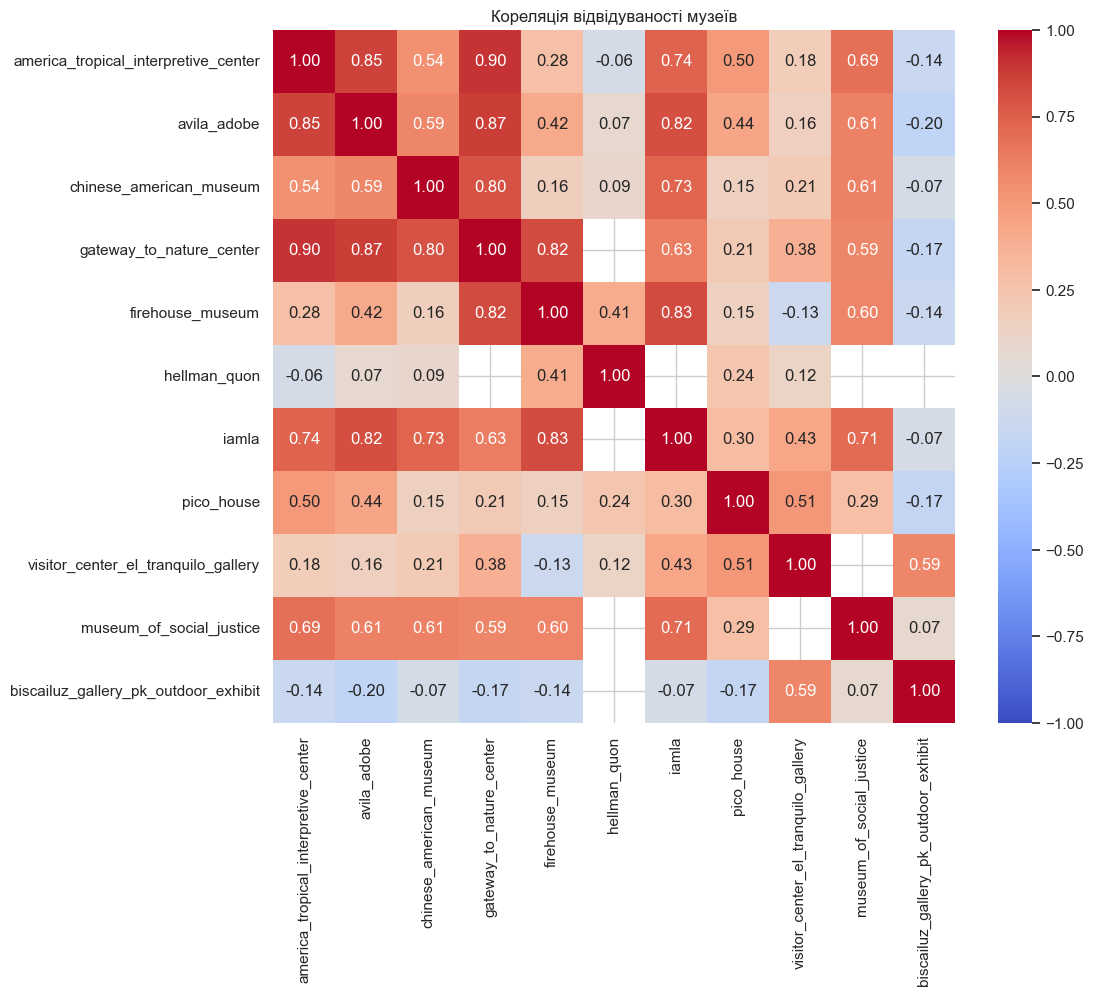

In [11]:
corr = df[museums].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Кореляція відвідуваності музеїв')
plt.show()

**Висновок.** Найсильніше пов'язана відвідуваність America Tropical Interpretive Center і Avila Adobe (0,85), а також Gateway to Nature Center з America Tropical та Avila Adobe (0,90 і 0,87). Ці об'єкти розташовані поруч, тому люди часто відвідують їх разом. Біля Biscailuz Gallery коефіцієнти слабкі або від'ємні. Для Hellman Quon частина клітинок порожня, бо періоди його даних не перетинаються з періодами деяких інших музеїв, і кореляцію там порахувати неможливо.

### Візуалізація відвідуваності засобами Seaborn

Побудуйте чотири графіки за наведеною тематикою. Поясніть у висновках, яку інформацію найкраще відображає кожний тип графіка.

### Завдання 12. Лінійний графік

Побудуйте **лінійний графік** зміни кількості відвідувачів **Avila Adobe** за місяцями. Підпишіть осі й заголовок.

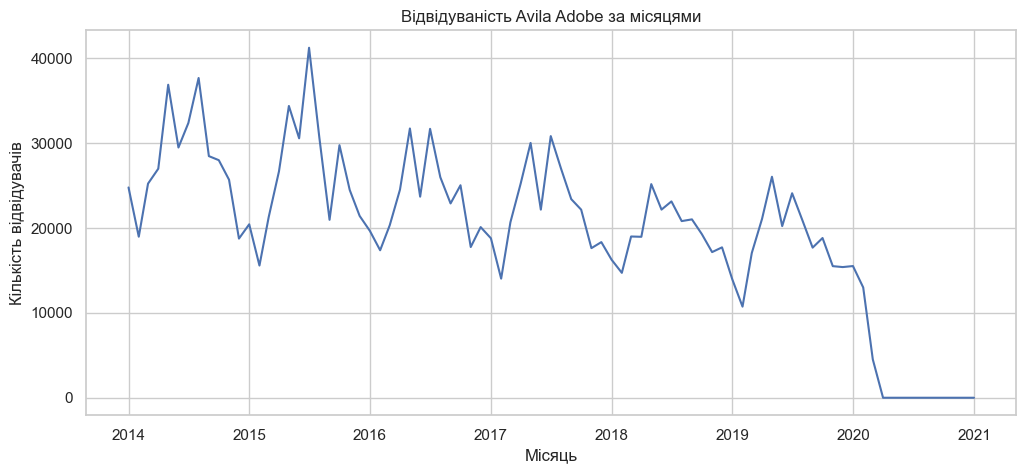

In [12]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x='month', y='avila_adobe')
plt.title('Відвідуваність Avila Adobe за місяцями')
plt.xlabel('Місяць')
plt.ylabel('Кількість відвідувачів')
plt.show()

Лінійний графік добре показує зміну показника в часі. Видно сезонні коливання з піками навесні та влітку, поступове зниження відвідуваності після 2015 року і падіння майже до нуля з березня 2020 року, коли музеї закрилися через пандемію.

### Завдання 13. Діаграма розмаху

Побудуйте **boxplot** для дослідження розподілу місячної відвідуваності **Chinese American Museum** за роками.

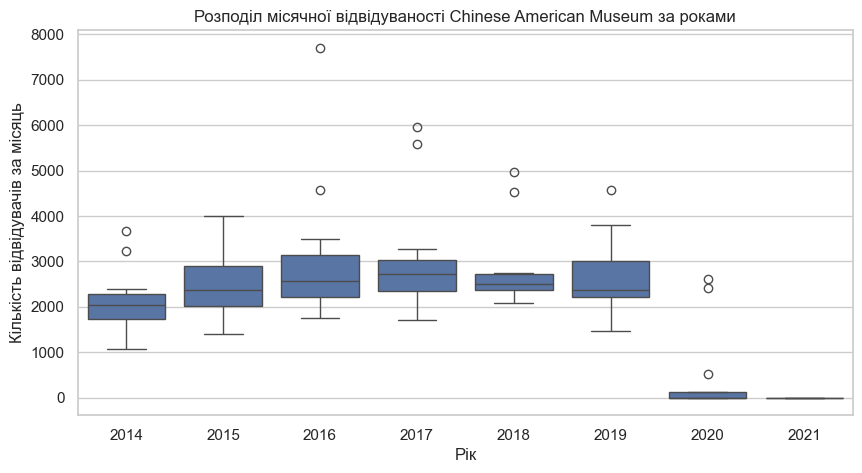

In [13]:
df['year'] = df['month'].dt.year

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='year', y='chinese_american_museum')
plt.title('Розподіл місячної відвідуваності Chinese American Museum за роками')
plt.xlabel('Рік')
plt.ylabel('Кількість відвідувачів за місяць')
plt.show()

Boxplot дозволяє порівняти розподіл за роками: медіану, розкид і викиди. У 2014–2019 роках медіана трималася в межах 2000–2700 відвідувачів на місяць. Окремі місяці з великою кількістю відвідувачів видно як викиди. У 2020 та 2021 роках значення майже нульові через закриття музею.

### Завдання 14. Гістограма

Побудуйте **гістограму** кількості відвідувачів **Gateway to Nature Center** за місяць. Використайте лише фактично наявні значення: не створюйте штучний пік шляхом заповнення численних пропусків середнім.

Кількість місяців з даними: 32


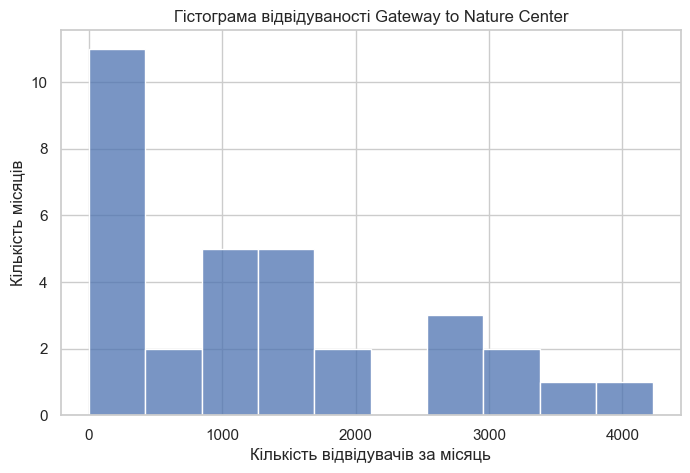

In [14]:
gateway = df['gateway_to_nature_center'].dropna()
print('Кількість місяців з даними:', len(gateway))

plt.figure(figsize=(8, 5))
sns.histplot(gateway, bins=10)
plt.title('Гістограма відвідуваності Gateway to Nature Center')
plt.xlabel('Кількість відвідувачів за місяць')
plt.ylabel('Кількість місяців')
plt.show()

Гістограма показує, як часто зустрічаються різні значення. Для побудови використано лише 32 фактичні значення. Великий стовпчик біля нуля – це місяці 2020 року, коли центр був закритий, а не штучний пік від заповнення пропусків.

### Завдання 15. Стовпчикова діаграма

Побудуйте **barplot** із середньомісячною кількістю відвідувачів для кожного музею. Впорядкуйте музеї за спаданням показника та забезпечте читабельність підписів.

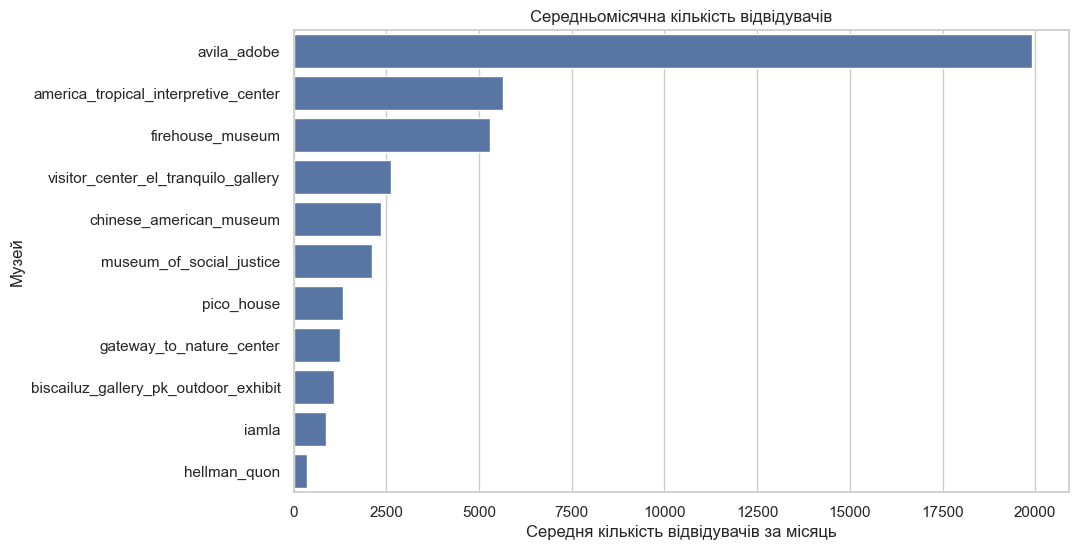

In [15]:
mean_sorted = df[museums].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=mean_sorted.values, y=mean_sorted.index)
plt.title('Середньомісячна кількість відвідувачів')
plt.xlabel('Середня кількість відвідувачів за місяць')
plt.ylabel('Музей')
plt.show()

Barplot зручний для порівняння одного показника між категоріями. Avila Adobe з великим відривом лідирує (близько 19 900 відвідувачів на місяць), далі йдуть America Tropical Interpretive Center та Firehouse Museum. Найменше відвідувачів у Hellman Quon. Горизонтальні стовпчики я обрав, щоб довгі назви музеїв не накладалися.

## Частина 2. Датасет Penguins

Використайте датасет **Penguins** (наприклад, із наборів даних Seaborn). Проведіть його первинне дослідження та створіть **п’ять різних візуалізацій** із використанням Seaborn.

**Вимоги до графіків:** типи графіків **не повинні повторювати приклади з лекції**; добирайте графіки відповідно до типів ознак і дослідницьких запитань. Для кожного графіка зазначте, який зв’язок, розподіл або порівняння він демонструє.

### Завдання 16. Завантаження та огляд Penguins

Завантажте датасет Penguins, виведіть перші п’ять рядків, типи ознак та кількість пропущених значень.

In [16]:
penguins = sns.load_dataset('penguins')
display(penguins.head())
print(penguins.dtypes)
print('\nПропущені значення:')
print(penguins.isna().sum())
print('\nРозмірність:', penguins.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

Пропущені значення:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Розмірність: (344, 7)


### Завдання 17. Візуалізація Penguins — графік 1

Оберіть запитання до даних і побудуйте **графік 1** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

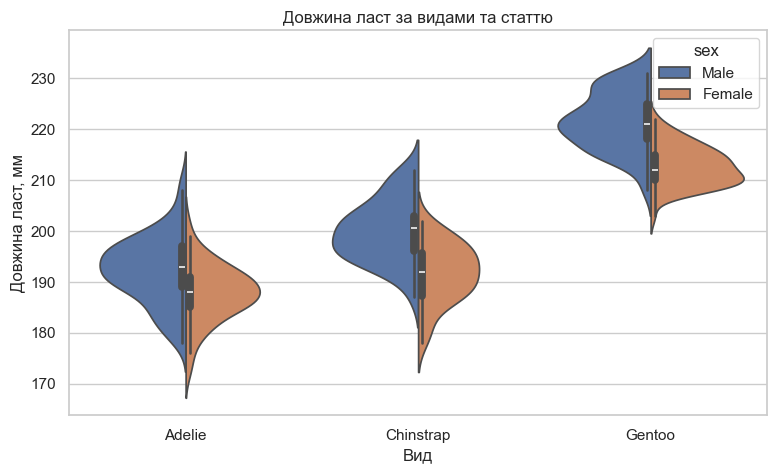

In [17]:
# Графік 1 (violinplot): як розподілена довжина ласт у різних видів і чи відрізняється вона за статтю
plt.figure(figsize=(9, 5))
sns.violinplot(data=penguins, x='species', y='flipper_length_mm', hue='sex', split=True)
plt.title('Довжина ласт за видами та статтю')
plt.xlabel('Вид')
plt.ylabel('Довжина ласт, мм')
plt.show()

**Що показує графік 1.** Violinplot показує форму розподілу довжини ласт для кожного виду окремо для самців і самиць. У Gentoo ласти помітно довші (близько 210–230 мм), ніж у Adelie і Chinstrap. В усіх видів самці мають довші ласти, ніж самиці.

### Завдання 18. Візуалізація Penguins — графік 2

Оберіть запитання до даних і побудуйте **графік 2** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

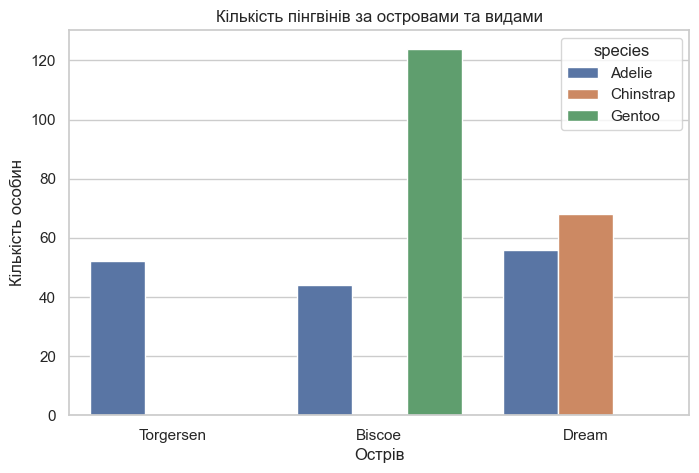

In [18]:
# Графік 2 (countplot): скільки пінгвінів кожного виду живе на кожному острові
plt.figure(figsize=(8, 5))
sns.countplot(data=penguins, x='island', hue='species')
plt.title('Кількість пінгвінів за островами та видами')
plt.xlabel('Острів')
plt.ylabel('Кількість особин')
plt.show()

**Що показує графік 2.** Countplot порівнює кількість особин за категоріями. Adelie живуть на всіх трьох островах, Gentoo – тільки на Biscoe, а Chinstrap – тільки на Dream. Найбільше пінгвінів на острові Biscoe.

### Завдання 19. Візуалізація Penguins — графік 3

Оберіть запитання до даних і побудуйте **графік 3** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

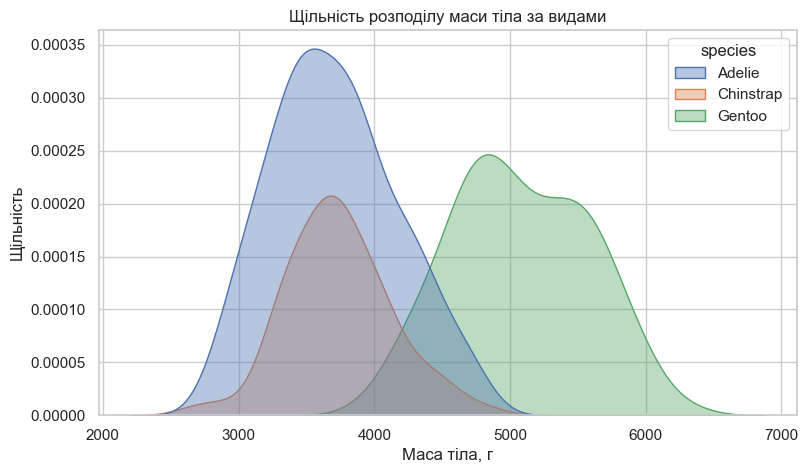

In [19]:
# Графік 3 (kdeplot): порівняння розподілів маси тіла трьох видів
plt.figure(figsize=(9, 5))
sns.kdeplot(data=penguins, x='body_mass_g', hue='species', fill=True, alpha=0.4)
plt.title('Щільність розподілу маси тіла за видами')
plt.xlabel('Маса тіла, г')
plt.ylabel('Щільність')
plt.show()

**Що показує графік 3.** KDE-графік показує згладжений розподіл маси тіла. Розподіли Adelie і Chinstrap майже збігаються (близько 3500–3800 г), а Gentoo значно важчі (близько 5000 г). Тобто за масою можна відрізнити Gentoo від інших видів, але не Adelie від Chinstrap.

### Завдання 20. Візуалізація Penguins — графік 4

Оберіть запитання до даних і побудуйте **графік 4** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

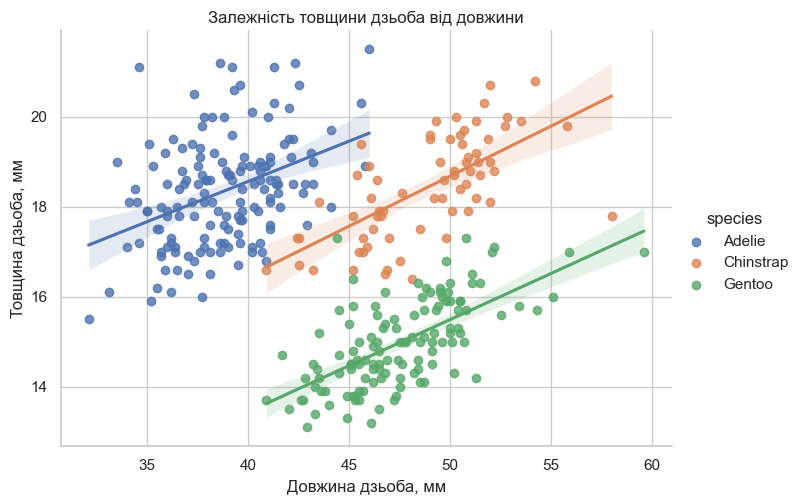

In [20]:
# Графік 4 (lmplot): зв'язок між довжиною і товщиною дзьоба всередині кожного виду
g = sns.lmplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species', height=5, aspect=1.4)
g.set_axis_labels('Довжина дзьоба, мм', 'Товщина дзьоба, мм')
plt.title('Залежність товщини дзьоба від довжини')
plt.show()

**Що показує графік 4.** Lmplot показує лінійну залежність між двома числовими ознаками з лінією регресії. Усередині кожного виду між довжиною і товщиною дзьоба є прямий зв'язок: довший дзьоб буває товщим. Якщо ж не розділяти пінгвінів на види, зв'язок здається оберненим (парадокс Сімпсона), тому вид обов'язково треба враховувати.

### Завдання 21. Візуалізація Penguins — графік 5

Оберіть запитання до даних і побудуйте **графік 5** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

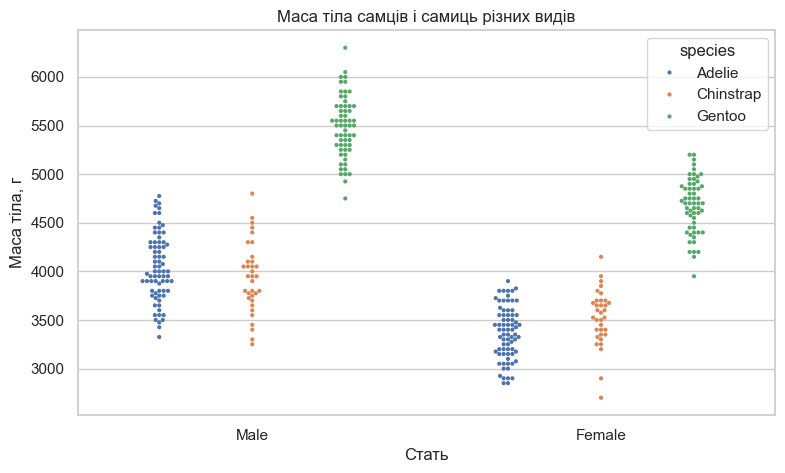

In [21]:
# Графік 5 (swarmplot): маса кожної особини за статтю та видом, видно і розподіл, і кількість
plt.figure(figsize=(9, 5))
sns.swarmplot(data=penguins.dropna(subset=['sex']), x='sex', y='body_mass_g', hue='species', dodge=True, size=3)
plt.title('Маса тіла самців і самиць різних видів')
plt.xlabel('Стать')
plt.ylabel('Маса тіла, г')
plt.show()

**Що показує графік 5.** Swarmplot показує кожну особину окремою точкою, тому видно і розподіл, і кількість спостережень. В усіх трьох видів самці важчі за самиць, а найважчі особини – самці Gentoo (до 6000 г і більше).

## Висновки

У музеях Лос-Анджелеса відвідуваність має чітку сезонність: найбільше відвідувачів у травні та влітку, найменше взимку. Найпопулярніший об'єкт – Avila Adobe. У 2020 році відвідуваність усіх музеїв впала майже до нуля через пандемію. Частина музеїв має дані лише за окремі роки, тому середні значення треба порівнювати з урахуванням кількості місяців, а для сум брати однаковий набір музеїв. Заповнення пропусків середнім або нулями спотворило б результати, тому розрахунки виконувались лише за фактичними даними.

У даних Penguins види добре розрізняються за розмірами: Gentoo найбільші за масою та довжиною ласт, самці в усіх видів більші за самиць, а кожен вид пов'язаний з певними островами. Для часових рядів найкраще підійшов `lineplot`, для порівняння розподілів – `boxplot`, `violinplot` і `kdeplot`, для кореляцій – `heatmap`, а для зв'язку двох числових ознак – `lmplot`.